# India Weather Analysis & Prediction
## 2: Exploratory Data Analysis (EDA)

**Goal:** Understand the climate patterns in the data *before* modeling.

**Input:** `data/processed/india_weather_daily.csv` from Notebook 1

## 1. Setup

In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 30)

# Folder for charts (reuse these in your README and LinkedIn post)
FIG_DIR = Path("reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 2. Load data

In [3]:
CSV = Path("data/processed/india_weather_daily.csv")

# If the file is not in this Colab session, upload it manually
if not CSV.exists():
    try:
        from google.colab import files        # type: ignore # only available in Google Colab
        print("Upload india_weather_daily.csv")
        uploaded = files.upload()
        CSV = Path(list(uploaded.keys())[0])
    except ImportError:
        raise FileNotFoundError(
            "data/processed/india_weather_daily.csv not found. Run Notebook 1 first, and make sure the "
            "notebook working folder is the project root (setting: jupyter.notebookFileRoot)."
        )

df = pd.read_csv(CSV, parse_dates=["date"])
print(f"Rows: {len(df):,} | Cities: {df['city'].nunique()} | "
      f"Period: {df['date'].min().date()} -> {df['date'].max().date()}")
df.head()

Rows: 133,816 | Cities: 8 | Period: 1981-01-01 -> 2026-10-18


,date,city,temp_mean,temp_max,temp_min,rainfall_mm,humidity_pct,wind_speed_ms,pressure_kpa,year,month,day_of_year,season
0,1981-01-01,Bengaluru,21.00,29.10,14.62,0.00,68.68,2.85,91.90,1981,1,1,Winter
1,1981-01-02,Bengaluru,21.53,29.12,15.58,10.08,69.01,1.91,91.87,1981,1,2,Winter
2,1981-01-03,Bengaluru,21.14,29.07,16.04,20.64,68.67,2.41,91.88,1981,1,3,Winter
3,1981-01-04,Bengaluru,20.84,29.33,15.24,0.00,64.00,2.23,91.90,1981,1,4,Winter
4,1981-01-05,Bengaluru,20.61,30.22,13.77,0.00,62.44,1.73,91.93,1981,1,5,Winter


In [3]:
# Full years only (the current year is partial and would bias yearly stats)
days_per_year = df.groupby(["city", "year"]).size().unstack(0)
full_years = days_per_year.index[(days_per_year >= 365).all(axis=1)]
df_full = df[df["year"].isin(full_years)]
print(f"Full years used for yearly stats: {full_years.min()} - {full_years.max()}")

# Monthly mean temperature (cities as columns), dropping an incomplete last month
monthly = (df.set_index("date").groupby("city")["temp_mean"]
             .resample("MS").mean().unstack(0))
last_day = df["date"].max()
if last_day != last_day + pd.offsets.MonthEnd(0):
    monthly = monthly.iloc[:-1]
monthly.tail()

Full years used for yearly stats: 1981 - 2025


city,Bengaluru,Chennai,Delhi,Hyderabad,Jaipur,Kolkata,Mumbai,Shimla
date,,,,,,,,
2026-05-01,26.964839,31.009355,33.954516,33.864194,33.892903,30.633226,32.200645,27.351935
2026-06-01,25.119333,31.352333,35.579333,29.657000,33.442000,30.288000,30.846667,29.364333
2026-07-01,25.577097,31.912258,31.205484,27.660000,31.442258,28.499677,27.366774,27.368065
2026-08-01,25.401613,30.468387,29.200000,26.542258,29.635484,28.649032,26.978065,25.746452
2026-09-01,25.713000,29.814667,27.052000,26.574333,27.985667,28.055667,27.090000,23.998667


## 3. Seasonality: average temperature by month

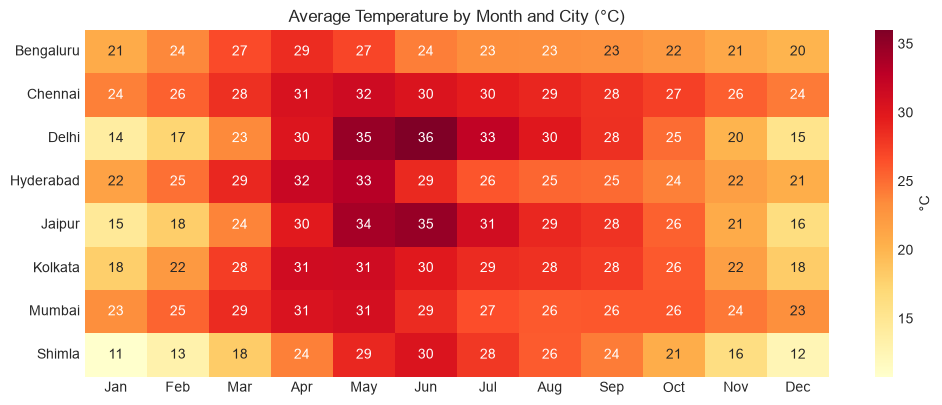

city
Delhi        22.1
Jaipur       20.2
Shimla       19.7
Kolkata      13.4
Hyderabad    12.5
Bengaluru     8.4
Mumbai        7.8
Chennai       7.5
Name: seasonal range (°C), dtype: float64


In [4]:
clim = df.pivot_table(index="city", columns="month", values="temp_mean", aggfunc="mean")
clim.columns = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

fig, ax = plt.subplots(figsize=(12, 4.5))
sns.heatmap(clim, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "°C"}, ax=ax)
ax.set_title("Average Temperature by Month and City (°C)")
ax.set_ylabel("")
save_fig(fig, "01_monthly_temperature_heatmap")
plt.show()

# Seasonal range = hottest month minus coldest month
print((clim.max(axis=1) - clim.min(axis=1)).sort_values(ascending=False).round(1).rename("seasonal range (°C)"))

## 4. Trend & seasonality: STL decomposition
STL splits a monthly series into **trend + seasonal + residual**. Change `CITY` to explore others.

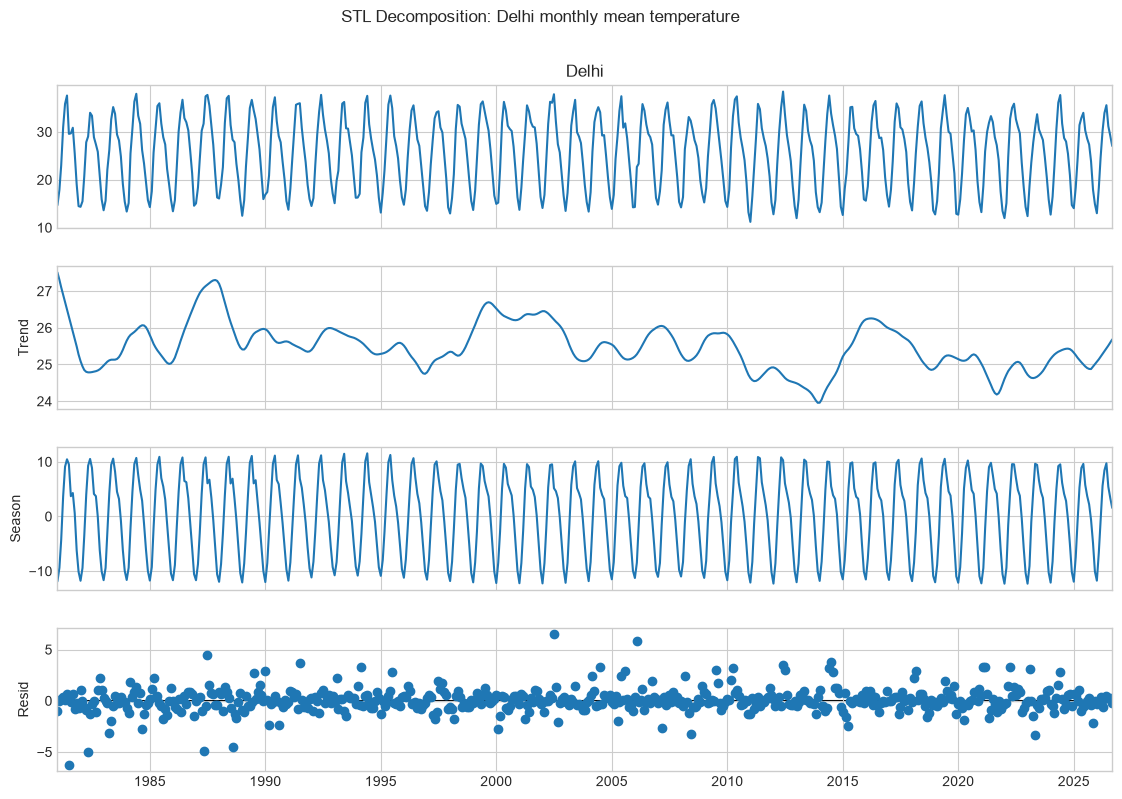

Delhi: STL trend, last 10 years minus first 10 years = -0.70 °C


In [5]:
CITY = "Delhi"

res = STL(monthly[CITY].dropna(), period=12, robust=True).fit()
fig = res.plot()
fig.set_size_inches(12, 8)
fig.suptitle(f"STL Decomposition: {CITY} monthly mean temperature", y=1.02)
save_fig(fig, f"02_stl_{CITY.lower()}")
plt.show()

# Compare 10-year averages (the first and last months of an STL trend are unreliable edge estimates)
trend_change = res.trend.iloc[-120:].mean() - res.trend.iloc[:120].mean()
print(f"{CITY}: STL trend, last 10 years minus first 10 years = {trend_change:+.2f} °C")

## 5. Stationarity tests
- **ADF:** p < 0.05 → stationary
- **KPSS:** p < 0.05 → *not* stationary

Raw temperature has strong seasonality. Removing the monthly average (the *anomaly*) shows whether a trend remains.

In [6]:
def stationarity_row(series):
    series = series.dropna()
    return {
        "ADF p-value": adfuller(series, autolag="AIC")[1],
        "KPSS p-value": kpss(series, regression="c", nlags="auto")[1],
    }

rows = []
for city in monthly.columns:
    s = monthly[city].dropna()
    anomaly = s - s.groupby(s.index.month).transform("mean")
    raw = stationarity_row(s)
    anom = stationarity_row(anomaly)
    rows.append({
        "city": city,
        "raw ADF p": raw["ADF p-value"], "raw KPSS p": raw["KPSS p-value"],
        "anomaly ADF p": anom["ADF p-value"], "anomaly KPSS p": anom["KPSS p-value"],
    })

stationarity = pd.DataFrame(rows).set_index("city").round(4)
stationarity

,raw ADF p,raw KPSS p,anomaly ADF p,anomaly KPSS p
city,,,,
Bengaluru,0.0000,0.10,0.0,0.0487
Chennai,0.0000,0.10,0.0,0.0433
Delhi,0.0000,0.10,0.0,0.0561
Hyderabad,0.0000,0.10,0.0,0.1000
Jaipur,0.0003,0.10,0.0,0.1000
Kolkata,0.0000,0.10,0.0,0.1000
Mumbai,0.0000,0.01,0.0,0.0100
Shimla,0.0001,0.10,0.0,0.1000


## 6. Autocorrelation (ACF / PACF) of monthly anomalies

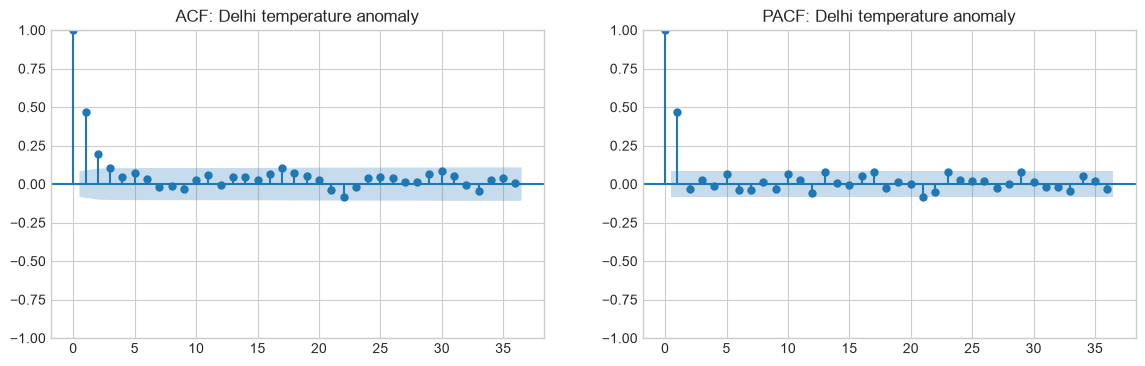

In [7]:
s = monthly[CITY].dropna()
anomaly = s - s.groupby(s.index.month).transform("mean")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(anomaly, lags=36, ax=axes[0])
plot_pacf(anomaly, lags=36, ax=axes[1], method="ywm")
axes[0].set_title(f"ACF: {CITY} temperature anomaly")
axes[1].set_title(f"PACF: {CITY} temperature anomaly")
save_fig(fig, f"03_acf_pacf_{CITY.lower()}")
plt.show()

## 7. Warming rate per decade

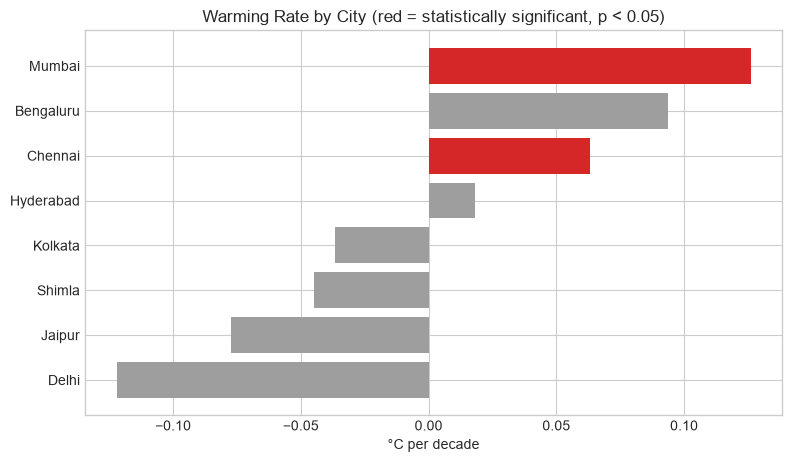

,warming_per_decade,p_value,r_squared,significant
city,,,,
Delhi,-0.122,0.081,0.069,False
Jaipur,-0.077,0.280,0.027,False
Shimla,-0.045,0.493,0.011,False
Kolkata,-0.037,0.347,0.021,False
Hyderabad,0.018,0.716,0.003,False
Chennai,0.063,0.037,0.097,True
Bengaluru,0.094,0.067,0.076,False
Mumbai,0.126,0.000,0.281,True


In [8]:
annual = df_full.pivot_table(index="year", columns="city", values="temp_mean", aggfunc="mean")

rows = []
for city in annual.columns:
    r = stats.linregress(annual.index, annual[city])
    rows.append({"city": city, "warming_per_decade": r.slope * 10,
                 "p_value": r.pvalue, "r_squared": r.rvalue ** 2})

warming = pd.DataFrame(rows).set_index("city").sort_values("warming_per_decade")
warming["significant"] = warming["p_value"] < 0.05

fig, ax = plt.subplots(figsize=(9, 5))
colors = warming["significant"].map({True: "#d62728", False: "#9e9e9e"})
ax.barh(warming.index, warming["warming_per_decade"], color=colors)
ax.set_xlabel("°C per decade")
ax.set_title("Warming Rate by City (red = statistically significant, p < 0.05)")
save_fig(fig, "04_warming_per_decade")
plt.show()

warming.round(3)

### Warming stripes
A popular visual for LinkedIn: each bar is one year, red = warmer than the 1981-2010 average.

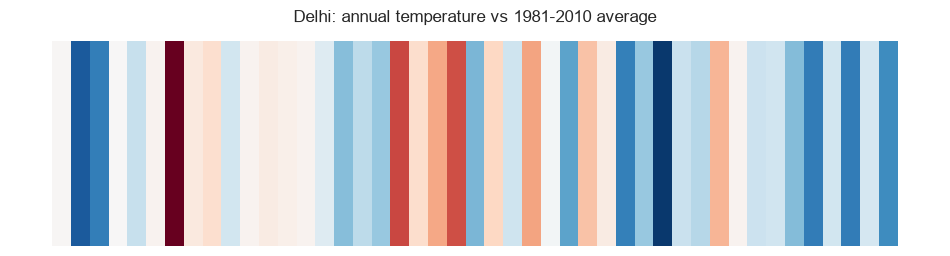

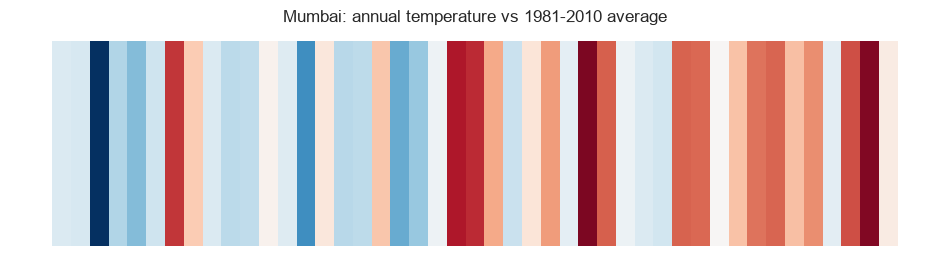

In [9]:
def warming_stripes(city):
    a = annual[city]
    anom = a - a.loc[1981:2010].mean()
    vmax = anom.abs().max()
    norm = plt.Normalize(-vmax, vmax)
    fig, ax = plt.subplots(figsize=(12, 2.8))
    ax.bar(anom.index, 1, width=1.0, color=plt.cm.RdBu_r(norm(anom.values)))
    ax.set_axis_off()
    ax.set_title(f"{city}: annual temperature vs 1981-2010 average", fontsize=12)
    save_fig(fig, f"05_warming_stripes_{city.lower()}")
    plt.show()

warming_stripes("Delhi")
warming_stripes("Mumbai")

## 8. Hot days (heatwave proxy)
A fixed threshold like 40 °C is misleading here: this data is gridded (about 50 km) and each grid cell has its own elevation and bias (a Himalayan city like Shimla would show many "40 °C days", which is unrealistic).

So we use a **relative threshold**: a *hot day* is a day when the maximum temperature exceeds that city's own **95th percentile in 1981-2010**. By definition, that baseline period has about 18 hot days per year, so any increase afterwards is a real shift, comparable across cities.

Hot-day thresholds (95th percentile of daily max, 1981-2010):
city
Bengaluru    37.5
Chennai      38.0
Delhi        44.9
Hyderabad    41.8
Jaipur       43.2
Kolkata      40.7
Mumbai       40.2
Shimla       39.0 



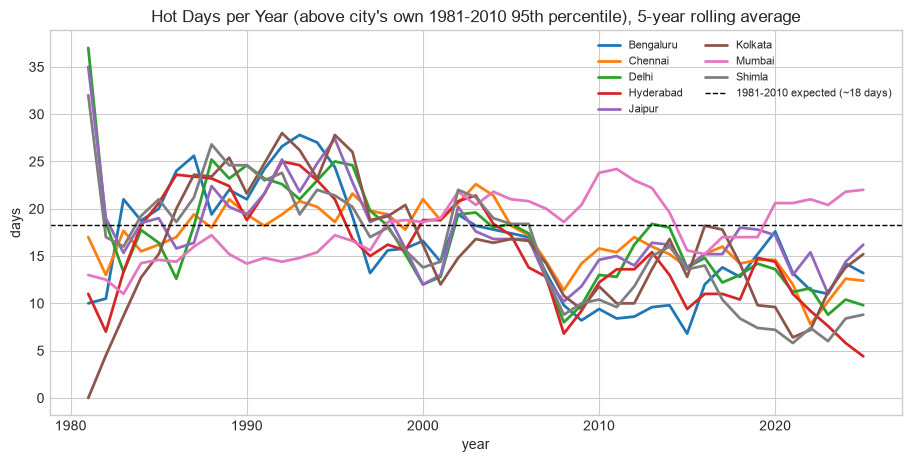

city,Bengaluru,Chennai,Delhi,Hyderabad,Jaipur,Kolkata,Mumbai,Shimla
decade,,,,,,,,
1980,20.6,18.6,20.8,20.6,19.4,19.8,14.8,22.2
1990,21.4,19.0,19.1,19.3,20.3,21.8,17.1,18.8
2000,13.0,17.8,13.9,13.8,14.3,12.9,21.1,14.5
2010,12.5,14.9,16.1,13.9,17.0,13.3,18.3,11.7
2020,13.0,11.0,9.2,4.8,15.2,12.8,23.3,7.7


In [10]:
baseline = df_full[df_full["year"].between(1981, 2010)]
threshold = baseline.groupby("city")["temp_max"].quantile(0.95)
print("Hot-day thresholds (95th percentile of daily max, 1981-2010):")
print(threshold.round(1).to_string(), "\n")

d = df_full.assign(hot=df_full["temp_max"] > df_full["city"].map(threshold))
hot_days = d.groupby(["year", "city"])["hot"].sum().unstack()

fig, ax = plt.subplots(figsize=(11, 5))
hot_days.rolling(5, min_periods=1).mean().plot(ax=ax, lw=2)
ax.axhline(18.25, color="k", ls="--", lw=1, label="1981-2010 expected (~18 days)")
ax.set_title("Hot Days per Year (above city's own 1981-2010 95th percentile), 5-year rolling average")
ax.set_ylabel("days")
ax.legend(ncol=2, fontsize=8)
save_fig(fig, "06_hot_days")
plt.show()

# Decade averages
decade = (hot_days.index // 10 * 10).rename("decade")
hot_days.groupby(decade).mean().round(1)

## 9. Monsoon rainfall variability
Total June-September rainfall each year. A higher **coefficient of variation (CV)** means a less predictable monsoon.

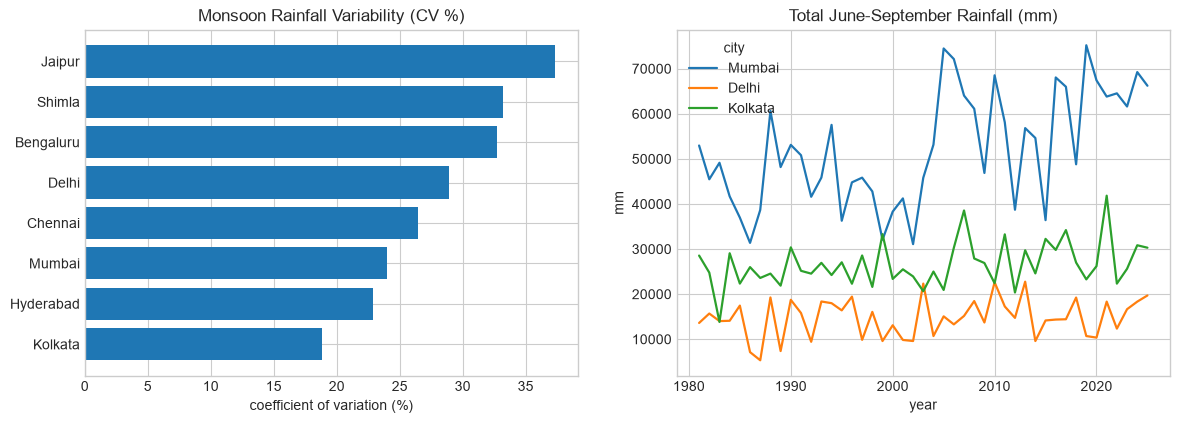

Note: Chennai gets most rain from the NE monsoon (Oct-Dec), so a June-Sept total understates it.


In [11]:
monsoon = (df_full[df_full["season"] == "Monsoon"]
           .groupby(["year", "city"])["rainfall_mm"].sum().unstack())

cv = (monsoon.std() / monsoon.mean() * 100).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].barh(cv.index, cv.values, color="#1f77b4")
axes[0].set_title("Monsoon Rainfall Variability (CV %)")
axes[0].set_xlabel("coefficient of variation (%)")

monsoon[["Mumbai", "Delhi", "Kolkata"]].plot(ax=axes[1], lw=1.6)
axes[1].set_title("Total June-September Rainfall (mm)")
axes[1].set_ylabel("mm")
save_fig(fig, "07_monsoon_variability")
plt.show()

print("Note: Chennai gets most rain from the NE monsoon (Oct-Dec), so a June-Sept total understates it.")

## 10. Validation against a second source (ERA5)
Section 8 showed hot days falling in almost every city at the same time. Before believing that, we compare NASA POWER with **ERA5**, another independent reanalysis (free via the Open-Meteo archive API, no key needed).

We compare (a) yearly temperature *anomalies* and (b) hot days using each source's own 95th-percentile threshold.

In [12]:
import time
import requests

CITY_COORDS = {
    "Delhi": (28.61, 77.21), "Mumbai": (19.08, 72.88), "Chennai": (13.08, 80.27),
    "Kolkata": (22.57, 88.36), "Bengaluru": (12.97, 77.59), "Hyderabad": (17.38, 78.48),
    "Jaipur": (26.91, 75.79), "Shimla": (31.10, 77.17),
}
ERA5_DIR = Path("data/raw")
ERA5_DIR.mkdir(parents=True, exist_ok=True)
LAST_FULL_YEAR = int(full_years.max())

def era5_is_valid(d):
    # ~16,400 days expected for 1981-2025; reject empty or mostly-null responses
    return (len(d) > 16000) and (d[["era5_mean", "era5_max"]].isna().mean().max() < 0.05)

def fetch_era5(city, lat, lon, retries=4):
    cache = ERA5_DIR / f"era5_{city.lower()}_{LAST_FULL_YEAR}.csv"
    if cache.exists():
        cached = pd.read_csv(cache, parse_dates=["date"])
        if era5_is_valid(cached):
            return cached
        print(f"⚠ {city}: cached file is incomplete, downloading again")
    params = {
        "latitude": lat, "longitude": lon,
        "start_date": "1981-01-01", "end_date": f"{LAST_FULL_YEAR}-12-31",
        "daily": "temperature_2m_mean,temperature_2m_max",
        "timezone": "Asia/Kolkata",
    }
    for attempt in range(1, retries + 1):
        try:
            r = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=120)
            r.raise_for_status()
            d = pd.DataFrame(r.json()["daily"]).rename(columns={
                "time": "date", "temperature_2m_mean": "era5_mean", "temperature_2m_max": "era5_max"})
            d["date"] = pd.to_datetime(d["date"])
            if not era5_is_valid(d):
                raise KeyError(f"incomplete response ({len(d)} rows)")
            d.to_csv(cache, index=False)
            time.sleep(8)   # be polite to the free API (avoids 429 errors)
            return d
        except (requests.RequestException, KeyError) as e:
            print(f"⚠ {city}: attempt {attempt} failed ({e})")
            time.sleep(20 * attempt)
    return None

era5_frames = []
for city, (lat, lon) in CITY_COORDS.items():
    d = fetch_era5(city, lat, lon)
    if d is None:
        print(f"✘ {city}: skipped (could not download)")
        continue
    era5_frames.append(d.assign(city=city))
    print(f"✔ {city}")

era5 = pd.concat(era5_frames, ignore_index=True) if era5_frames else None
print("\nERA5 ready:" , era5 is not None)

✔ Delhi
✔ Mumbai
✔ Chennai
✔ Kolkata
✔ Bengaluru
✔ Hyderabad
✔ Jaipur
✔ Shimla

ERA5 ready: True


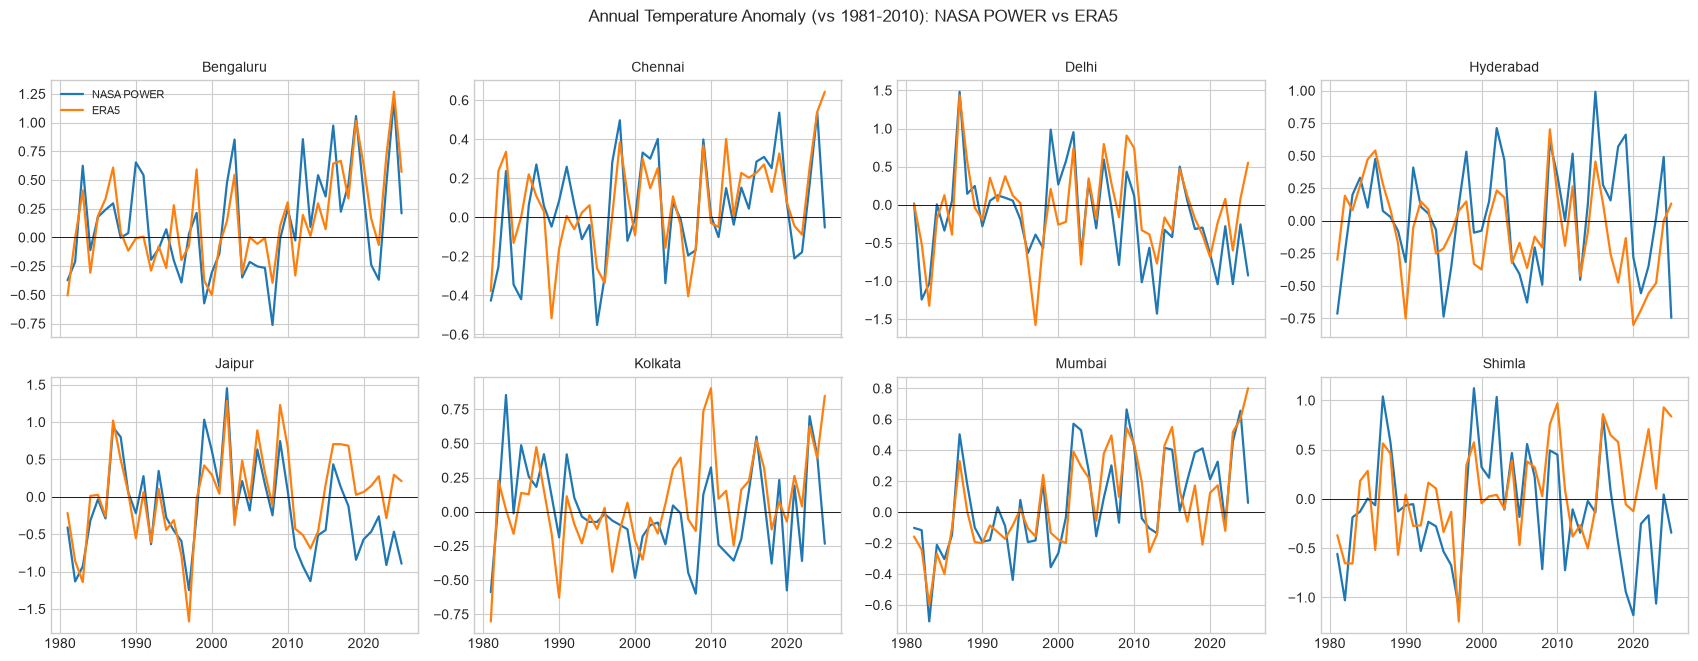

,correlation,NASA POWER (°C/decade),ERA5 (°C/decade)
city,,,
Bengaluru,0.77,0.09,0.14
Chennai,0.67,0.06,0.07
Delhi,0.69,-0.12,0.00
Hyderabad,0.58,0.02,-0.08
Jaipur,0.80,-0.08,0.13
Kolkata,0.50,-0.04,0.12
Mumbai,0.78,0.13,0.14
Shimla,0.52,-0.04,0.16


In [13]:
if era5 is None:
    print("ERA5 download failed. Re-run the cell above (the free API sometimes rate-limits).")
else:
    era5["year"] = era5["date"].dt.year
    era5_annual = era5.groupby(["year", "city"])["era5_mean"].mean().unstack()
    cities = [c for c in annual.columns
              if c in era5_annual.columns and era5_annual[c].notna().sum() > 30]
    not_checked = sorted(set(annual.columns) - set(cities))
    if not_checked:
        print("⚠ Not validated (missing ERA5 data):", not_checked, "- delete its file in data/raw/ and re-run the download cell")

    def anomaly(a):
        return a - a.loc[1981:2010].mean()

    rows = []
    fig, axes = plt.subplots(2, 4, figsize=(17, 6.5), sharex=True)
    for ax, c in zip(axes.ravel(), cities):
        x = anomaly(annual[c])
        y = anomaly(era5_annual[c].loc[x.index])
        sx = stats.linregress(x.index, x.values).slope * 10
        sy = stats.linregress(y.index, y.values).slope * 10
        rows.append({"city": c, "correlation": x.corr(y),
                     "NASA POWER (°C/decade)": sx, "ERA5 (°C/decade)": sy})
        ax.plot(x.index, x.values, label="NASA POWER", lw=1.6)
        ax.plot(y.index, y.values, label="ERA5", lw=1.6)
        ax.axhline(0, color="k", lw=0.6)
        ax.set_title(c, fontsize=10)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle("Annual Temperature Anomaly (vs 1981-2010): NASA POWER vs ERA5", y=1.01)
    fig.tight_layout()
    save_fig(fig, "08_validation_nasa_vs_era5")
    plt.show()

    validation = pd.DataFrame(rows).set_index("city")
    display(validation.round(2))

In [14]:
if era5 is not None:
    # Hot days using ERA5's own 95th percentile (same method as section 8)
    e = era5[era5["year"].isin(full_years)].copy()
    thr_e = e[e["year"].between(1981, 2010)].groupby("city")["era5_max"].quantile(0.95)
    e["hot"] = e["era5_max"] > e["city"].map(thr_e)
    hot_era5 = e.groupby(["year", "city"])["hot"].sum().unstack()

    def early_late_change(h):
        return h.loc[h.index >= 2010].mean() - h.loc[h.index < 2000].mean()

    change = pd.DataFrame({
        "NASA POWER": early_late_change(hot_days),
        "ERA5": early_late_change(hot_era5),
    }).round(1)
    change["same direction?"] = np.sign(change["NASA POWER"]) == np.sign(change["ERA5"])

    print("Change in hot days per year: (2010+) minus (before 2000)")
    display(change)

    agree = int(change["same direction?"].sum())
    print(f"\nThe two sources agree on the direction of change in {agree} of {len(change)} cities.")
    print(f"Median annual-anomaly correlation: {validation['correlation'].median():.2f}")
    print("\nHow to read this:")
    print("- High correlation and similar slopes -> NASA POWER trends are trustworthy.")
    print("- A large gap between the sources (especially in hot days) -> a data artifact; "
          "say so in your report and prefer the more consistent source for modeling.")

Change in hot days per year: (2010+) minus (before 2000)


,NASA POWER,ERA5,same direction?
city,,,
Bengaluru,-8.3,4.8,False
Chennai,-5.4,-5.2,True
Delhi,-6.4,-4.4,True
Hyderabad,-9.4,-8.0,True
Jaipur,-3.6,2.7,False
Kolkata,-7.7,4.6,False
Mumbai,4.2,14.2,True
Shimla,-10.2,-4.9,True



The two sources agree on the direction of change in 5 of 8 cities.
Median annual-anomaly correlation: 0.68

How to read this:
- High correlation and similar slopes -> NASA POWER trends are trustworthy.
- A large gap between the sources (especially in hot days) -> a data artifact; say so in your report and prefer the more consistent source for modeling.


## 11. Key insights (auto-generated)

In [15]:
fastest = warming["warming_per_decade"].idxmax()
slowest = warming["warming_per_decade"].idxmin()
n_sig = int(warming["significant"].sum())

early = hot_days.loc[hot_days.index < 2000].mean()
late = hot_days.loc[hot_days.index >= 2010].mean()
hot_change = (late - early).sort_values(ascending=False)

n_neg = int((warming["warming_per_decade"] < 0).sum())
print(f"1. {n_sig} of {len(warming)} cities show a statistically significant trend (p < 0.05); "
      f"{n_neg} show a negative (cooling) slope. Interpret with care: this is gridded model data.")
print(f"2. Fastest warming: {fastest} ({warming.loc[fastest, 'warming_per_decade']:.2f} °C/decade). "
      f"Slowest: {slowest} ({warming.loc[slowest, 'warming_per_decade']:.2f} °C/decade).")
print(f"3. Biggest rise in hot days (2010+ vs before 2000): {hot_change.index[0]} "
      f"(+{hot_change.iloc[0]:.1f} days/year).")
print(f"4. Most variable monsoon: {cv.index[-1]} (CV {cv.iloc[-1]:.0f}%). "
      f"Most stable: {cv.index[0]} (CV {cv.iloc[0]:.0f}%).")
if "validation" in globals():
    print(f"5. NASA POWER vs ERA5 yearly anomaly correlation: median {validation['correlation'].median():.2f}; "
          f"sources agree on hot-day direction in {int(change['same direction?'].sum())} of {len(change)} cities.")

1. 2 of 8 cities show a statistically significant trend (p < 0.05); 4 show a negative (cooling) slope. Interpret with care: this is gridded model data.
2. Fastest warming: Mumbai (0.13 °C/decade). Slowest: Delhi (-0.12 °C/decade).
3. Biggest rise in hot days (2010+ vs before 2000): Mumbai (+4.2 days/year).
4. Most variable monsoon: Jaipur (CV 37%). Most stable: Kolkata (CV 19%).
5. NASA POWER vs ERA5 yearly anomaly correlation: median 0.68; sources agree on hot-day direction in 5 of 8 cities.
